In [11]:
from roms_tools import Grid

In [3]:
project='/anvil/projects/x-ees250129/x-uheede/INPUT_files/Iceland2_MARBL_2024/RT_EMOD/'
datasets='/anvil/projects/x-ees250129/Datasets/'
model_name='Iceland2'
child_name='Iceland3'
grid_path='/anvil/projects/x-ees250129/x-uheede/INPUT_files/Iceland2_MARBL_2024/RT_EMOD/Iceland2_grid.nc'

CPU times: user 4min 17s, sys: 4.23 s, total: 4min 22s
Wall time: 24.4 s


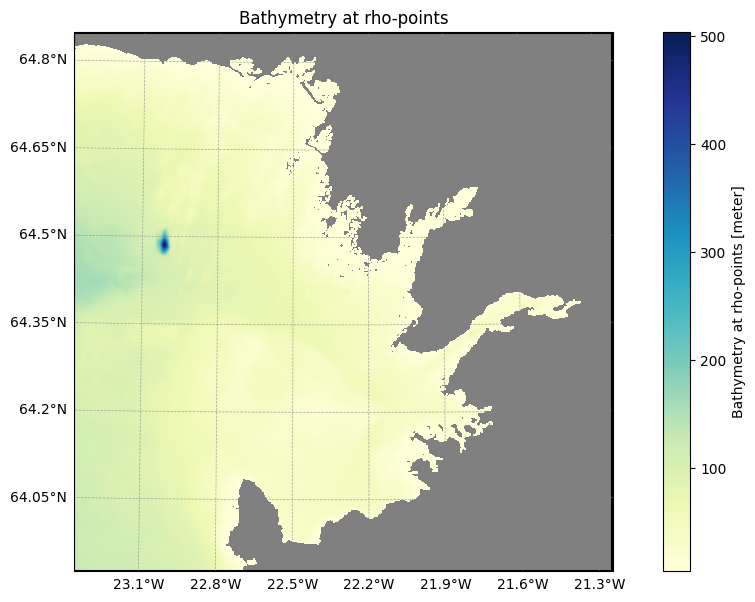

In [11]:
%%time

grid = Grid(
    nx=512,
    ny=512,
    size_x=102.4,
    size_y=102.4,
    center_lon=-22.3,
    center_lat=64.39,
    rot=0,
    mask_shapefile=datasets+"GSHHS/gshhg-shp-2.3.7/GSHHS_shp/f/GSHHS_f_L1.shp",
    close_narrow_channels=True,
    topography_source={
        "name": "EMOD",
        "path": datasets+"EMODnet_C2.nc"},
    N=60  # number of vertical layers
)

grid.plot()

In [14]:
ds_grid=grid.ds

In [7]:
from roms_tools import RiverForcing, Grid
from datetime import datetime

In [8]:
start_time = datetime(2023, 1, 1)
end_time = datetime(2024, 12, 31)

In [13]:
river_forcing = RiverForcing(
    grid=grid,
    start_time=start_time,
    end_time=end_time,
    convert_to_climatology="never",  # "never", "always", or "if_any_missing" (default)
    source = {
    "name": "GLOFAS",
    "path": '/anvil/projects/x-ees250129/Datasets/Rivers/processed_GloFAS/glofas_v4_rivers_daily.nc',
        }, 
    include_bgc=True
)

2026-09-16 12:20:06 - INFO - No river indices provided. Identifying all rivers within the ROMS domain and assigning each to the nearest coastal point.
2026-09-16 12:20:06 - INFO - Loading river discharge volume and tracer data from source...


[########################################] | 100% Completed | 1.02 sms


2026-09-16 12:20:07 - INFO - Creating 4 synthetic river(s) to handle overlapping entries.


In [15]:
river_forcing.ds.tracer_name

<xarray.DataArray 'tracer_name' (ntracers: 34)> Size: 1kB
array(['temp', 'salt', 'PO4', 'NO3', 'SiO3', 'NH4', 'Fe', 'Lig', 'O2',
       'DIC', 'DIC_ALT_CO2', 'ALK', 'ALK_ALT_CO2', 'DOC', 'DON', 'DOP',
       'DOPr', 'DONr', 'DOCr', 'zooC', 'spChl', 'spC', 'spP', 'spFe',
       'spCaCO3', 'diatChl', 'diatC', 'diatP', 'diatFe', 'diatSi',
       'diazChl', 'diazC', 'diazP', 'diazFe'], dtype='<U11')
Coordinates:
    tracer_name       (ntracers) <U11 1kB 'temp' 'salt' ... 'diazP' 'diazFe'
    tracer_unit       (ntracers) <U15 2kB 'degrees Celsius' 'PSU' ... 'mmol/m^3'
    tracer_long_name  (ntracers) <U43 6kB 'potential temperature' ... 'diazot...
  * ntracers          (ntracers) int64 272B 0 1 2 3 4 5 6 ... 28 29 30 31 32 33
Attributes:
    long_name:  Tracer name

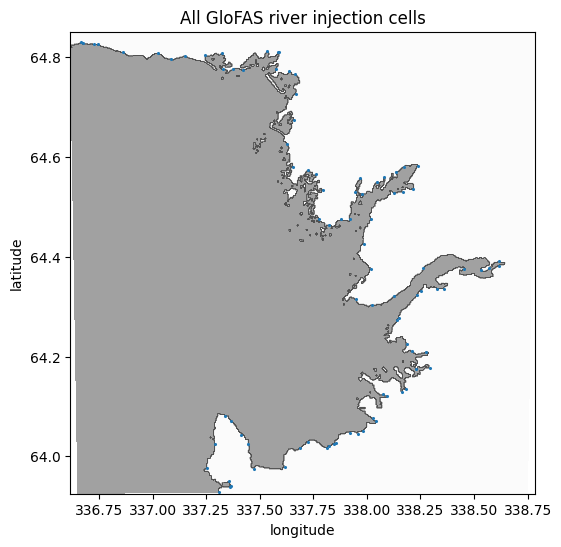

In [18]:
import numpy as np
import matplotlib.pyplot as plt

river_cells = river_forcing.ds["river_index"].values > 0
eta_rho, xi_rho = np.where(river_cells)

lon = river_forcing.grid.ds.lon_rho.values
lat = river_forcing.grid.ds.lat_rho.values
mask = river_forcing.grid.ds.mask_rho.values

fig, ax = plt.subplots(figsize=(6, 6))
ax.contourf(lon, lat, mask, cmap="Greys", alpha=0.4)
ax.scatter(
    lon[eta_rho, xi_rho],
    lat[eta_rho, xi_rho],
    s=6,
    marker=".",
    color="tab:blue",
)
ax.set_title("All GloFAS river injection cells")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude");


2026-09-11 12:29:24 - WARNING - Only the first 20 rivers will be plotted (received 99).


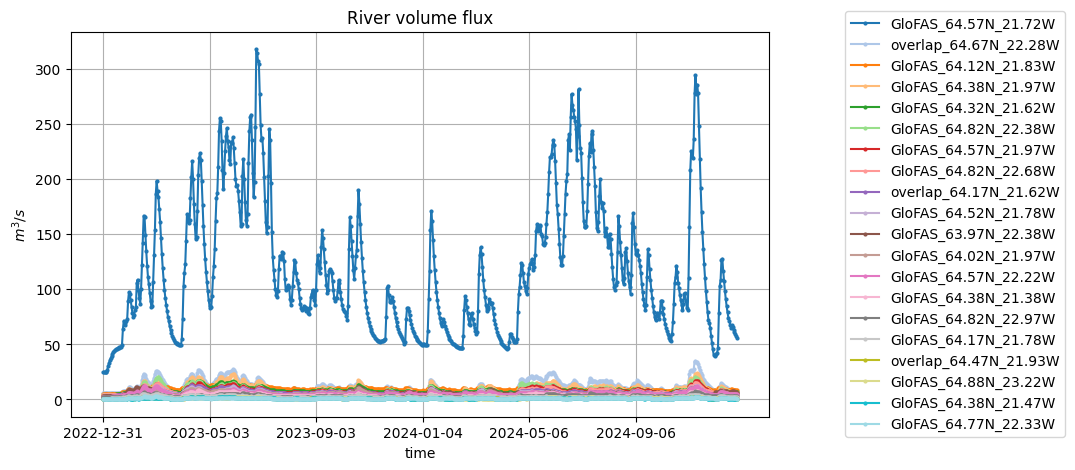

In [19]:
river_forcing.plot("river_volume")

In [10]:
river_forcing2 = RiverForcing(
    grid=grid,
    start_time=start_time,
    end_time=end_time,
    model_reference_date=datetime(2000, 1, 1), # this is the default
    include_bgc=True,
    source = {
    "name": "DAI",
    "path": "/anvil/projects/x-ees250129/Datasets/Iceland_river_dataset/Hvalfjordur_rivers_2024.nc",
    "climatology": False},
    bgc_source={"name": "CONSTANTS"}
)

NameError: name 'grid' is not defined

In [4]:
filepath = project+model_name+"_rivers2.nc"
river_forcing2.save(filepath=filepath)


NameError: name 'river_forcing2' is not defined

In [1]:
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
riv=xr.open_dataset(filepath)
riv.load()

NameError: name 'filepath' is not defined

In [23]:
## Create new array
#new_tracer = np.zeros_like(riv['river_tracer'].values)

## Temperature varies sinusoidally with time
#temp = 10 * np.sin(np.linspace(0, np.pi, riv.dims['river_time']))  # 12-month cycle

# Loop through tracers
#for i, tracer in enumerate(riv['tracer_name'].values):
#    if tracer == 'temp':
#        new_tracer[:, i, :] = temp[:, np.newaxis]  # vary with time
#    elif tracer == 'salt':
#        new_tracer[:, i, :] = 1
#    elif tracer == 'PO4':
#        new_tracer[:, i, :] = 0.4
#    elif tracer == 'NO3':
#        new_tracer[:, i, :] = 6
#    elif tracer == 'SiO3':
#        new_tracer[:, i, :] = 3
#    elif tracer == 'NH4':
#        new_tracer[:, i, :] = 0.4
#    elif tracer == 'Fe':
#        new_tracer[:, i, :] = 0.000197
#    elif tracer == 'Lig':
#        new_tracer[:, i, :] = 0.000465    
#    elif tracer == 'O2':
#        new_tracer[:, i, :] = 360    
#    elif tracer == 'DIC':
#        new_tracer[:, i, :] = 313    
#    elif tracer == 'DIC_ALT_CO2':
#        new_tracer[:, i, :] = 313  
#    elif tracer == 'ALK':
#        new_tracer[:, i, :] = 282 
#    elif tracer == 'ALK_ALT_CO2':
#        new_tracer[:, i, :] = 282 
#    else:
#        new_tracer[:, i, :] = 0.0
#riv['river_tracer'] = (riv['river_tracer'].dims, new_tracer)

# Updated river values 11/13/2026

# Create new array
new_tracer = np.zeros_like(riv['river_tracer'].values)

# Temperature varies sinusoidally with time
temp = 10 * np.sin(np.linspace(0, np.pi, riv.dims['river_time']))  # 12-month cycle

# Loop through tracers
for i, tracer in enumerate(riv['tracer_name'].values):
    if tracer == 'temp':
        new_tracer[:, i, :] = temp[:, np.newaxis]  # vary with time
    elif tracer == 'salt':
        new_tracer[:, i, :] = 1
    elif tracer == 'PO4':
        new_tracer[:, i, :] = 0.9
    elif tracer == 'NO3':
        new_tracer[:, i, :] = 12
    elif tracer == 'SiO3':
        new_tracer[:, i, :] = 14
    elif tracer == 'NH4':
        new_tracer[:, i, :] = 0.7
    elif tracer == 'Fe':
        new_tracer[:, i, :] = 0.000197
    elif tracer == 'Lig':
        new_tracer[:, i, :] = 0.000465    
    elif tracer == 'O2':
        new_tracer[:, i, :] = 300    
    elif tracer == 'DIC':
        new_tracer[:, i, :] = 313    
    elif tracer == 'DIC_ALT_CO2':
        new_tracer[:, i, :] = 313  
    elif tracer == 'ALK':
        new_tracer[:, i, :] = 282 
    elif tracer == 'ALK_ALT_CO2':
        new_tracer[:, i, :] = 282 
    else:
        new_tracer[:, i, :] = 0.0
riv['river_tracer'] = (riv['river_tracer'].dims, new_tracer)


/tmp/ipykernel_381926/608848569.py:5: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  temp = 10 * np.sin(np.linspace(0, np.pi, riv.dims['river_time']))  # 12-month cycle


In [24]:
riv.to_netcdf(project+model_name+"_rivers_modified2.nc")

In [25]:
riv['river_volume'][:] = riv['river_volume'].isel(river_time=7)*0.5

In [26]:
winter_months = [1, 2, 3, 4, 11, 12]

# Create a boolean mask for winter times
winter_mask = riv['abs_time'].dt.month.isin(winter_months)

# Scale river_volume to 40% of its original value during winter months
riv['river_volume'] = riv['river_volume'].where(~winter_mask, riv['river_volume'] * 0.4)

In [27]:
import pandas as pd
import xarray as xr

# 1. Create a deep copy for 2023
ds_2023 = riv.copy(deep=True)

# 2. Shift abs_time using .values to prevent creating a mismatched xarray Index
new_abs_time = pd.DatetimeIndex(riv['abs_time'].values) - pd.DateOffset(years=1)
ds_2023['abs_time'] = ('river_time', new_abs_time)

# 3. Shift river_time coordinate back 366 days
ds_2023['river_time'] = ds_2023['river_time'] - pd.Timedelta(days=366)

# 4. Concatenate 2023 and 2024 along river_time
riv = xr.concat([ds_2023, riv], dim='river_time')

In [28]:
riv

<xarray.Dataset> Size: 51MB
Dimensions:           (river_time: 24, nriver: 16, ntracers: 34, eta_rho: 514,
                       xi_rho: 514)
Coordinates:
    river_name        (nriver) object 128B 'HVAL10' 'overlap_HVAL7' ... 'HVAL7'
    abs_time          (river_time) datetime64[ns] 192B 2023-01-15 ... 2024-12-15
  * river_time        (river_time) timedelta64[ns] 192B 8414 days ... 9115 days
    tracer_name       (ntracers) object 272B 'temp' 'salt' ... 'diazP' 'diazFe'
    tracer_unit       (ntracers) object 272B 'degrees Celsius' ... 'mmol/m^3'
    tracer_long_name  (ntracers) object 272B 'potential temperature' ... 'dia...
  * nriver            (nriver) int32 64B 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16
  * ntracers          (ntracers) int32 136B 0 1 2 3 4 5 6 ... 28 29 30 31 32 33
Dimensions without coordinates: eta_rho, xi_rho
Data variables:
    river_volume      (river_time, nriver) float64 3kB 2.881 2.039 ... 0.0 0.0
    river_tracer      (river_time, ntracers, nriver) float32 52kB 0.0 ... 0.0
    river_index       (river_time, eta_rho, xi_rho) float32 25MB 0.0 0.0 ... 0.0
    river_fraction    (river_time, eta_rho, xi_rho) float32 25MB 0.0 0.0 ... 0.0

In [29]:
river_forcing.save(project+model_name+"_rivers_glofas.nc")

2026-09-11 12:29:25 - INFO - Writing the following NetCDF files:
/anvil/projects/x-ees250129/x-uheede/INPUT_files/Iceland2_MARBL_2024/RT_EMOD/Iceland2_rivers_glofas.nc


[PosixPath('/anvil/projects/x-ees250129/x-uheede/INPUT_files/Iceland2_MARBL_2024/RT_EMOD/Iceland2_rivers_glofas.nc')]

In [30]:
riv_glofas=xr.open_dataset('/anvil/projects/x-ees250129/x-uheede/INPUT_files/Iceland2_MARBL_2024/RT_EMOD/Iceland2_rivers_glofas.nc')
riv_glofas.load()

/tmp/ipykernel_381926/1488883627.py:1: FutureWarning: In a future version, xarray will not decode timedelta values based on the presence of a timedelta-like units attribute by default. Instead it will rely on the presence of a timedelta64 dtype attribute, which is now xarray's default way of encoding timedelta64 values. To continue decoding timedeltas based on the presence of a timedelta-like units attribute, users will need to explicitly opt-in by passing True or CFTimedeltaCoder(decode_via_units=True) to decode_timedelta. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  riv_glofas=xr.open_dataset('/anvil/projects/x-ees250129/x-uheede/INPUT_files/Iceland2_MARBL_2024/RT_EMOD/Iceland2_rivers_glofas.nc')


<xarray.Dataset> Size: 13MB
Dimensions:           (river_time: 733, nriver: 99, ntracers: 34, eta_rho: 514,
                       xi_rho: 514)
Coordinates:
    river_name        (nriver) object 792B 'GloFAS_64.57N_21.72W' ... 'GloFAS...
    abs_time          (river_time) datetime64[ns] 6kB 2022-12-31 ... 2025-01-01
  * river_time        (river_time) timedelta64[ns] 6kB 8400 days ... 9132 days
    tracer_name       (ntracers) object 272B 'temp' 'salt' ... 'diazP' 'diazFe'
    tracer_unit       (ntracers) object 272B 'degrees Celsius' ... 'mmol/m^3'
    tracer_long_name  (ntracers) object 272B 'potential temperature' ... 'dia...
  * nriver            (nriver) int32 396B 1 2 3 4 5 6 7 ... 93 94 95 96 97 98 99
  * ntracers          (ntracers) int32 136B 0 1 2 3 4 5 6 ... 28 29 30 31 32 33
Dimensions without coordinates: eta_rho, xi_rho
Data variables:
    river_volume      (river_time, nriver) float64 581kB 24.73 5.898 ... 0.0 0.0
    river_tracer      (river_time, ntracers, nriver) float32 10MB 15.62 ... 0.0
    river_index       (eta_rho, xi_rho) float32 1MB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    river_fraction    (eta_rho, xi_rho) float32 1MB 0.0 0.0 0.0 ... 0.0 0.0 0.0

In [31]:
import numpy as np
import pandas as pd
import xarray as xr

# Load datasets
# ds_grid: Grid dataset (contains lat_rho, lon_rho)
ds_hval=riv #Monthly Hvalfjörður dataset
ds_bay=riv_glofas  #Daily Bay dataset

# -------------------------------------------------------------------------
# Step 1: Map 2D Grid Cells (eta_rho, xi_rho) to Lat/Lon Bounding Box
# -------------------------------------------------------------------------
# Hvalfjörður bounds in degrees North and East (360 - W)
LAT_MIN, LAT_MAX = 64.25, 64.45
LON_MIN, LON_MAX = 338.1, 338.80  # 360 - 22.20W to 360 - 21.20W

# Create a 2D boolean grid mask (True for cells inside Hvalfjörður)
fjord_grid_mask = (
    (ds_grid['lat_rho'] >= LAT_MIN) & (ds_grid['lat_rho'] <= LAT_MAX) &
    (ds_grid['lon_rho'] >= LON_MIN) & (ds_grid['lon_rho'] <= LON_MAX)
)

# -------------------------------------------------------------------------
# Step 2: Identify and Mask Out Bay Rivers Inside the Fjord
# -------------------------------------------------------------------------
# Identify active river cells in ds_bay (river_index > 0)
bay_river_mask = (ds_bay['river_index'] > 0)

# Active bay river points that land inside the fjord bounding box
bay_rivers_in_fjord = bay_river_mask & fjord_grid_mask

# Remove bay river entries inside the fjord bounding box
ds_bay_cleaned = ds_bay.copy(deep=True)
ds_bay_cleaned['river_index'] = xr.where(bay_rivers_in_fjord, 0.0, ds_bay_cleaned['river_index'])
ds_bay_cleaned['river_fraction'] = xr.where(bay_rivers_in_fjord, 0.0, ds_bay_cleaned['river_fraction'])

# Zero out flow volume for any nriver sources that discharge inside the fjord
# Map 2D grid mask to active nriver source indices
if 'eta_rho' in ds_bay_cleaned['river_volume'].dims:
    # If river_volume is 2D/3D on spatial grid
    ds_bay_cleaned['river_volume'] = xr.where(fjord_grid_mask, 0.0, ds_bay_cleaned['river_volume'])

# -------------------------------------------------------------------------
# Step 3: Resample Daily Bay Dataset to Monthly Means using abs_time
# -------------------------------------------------------------------------
# 1. Swap dimension to abs_time for resampling
ds_bay_temp = ds_bay_cleaned.swap_dims({'river_time': 'abs_time'})

# 2. Resample along abs_time to Month-Start ('MS')
ds_bay_monthly = ds_bay_temp.resample(abs_time='MS').mean(dim='abs_time')

# 3. Align ds_hval to ds_bay_monthly using abs_time (datetime64 coordinate)
ds_hval_temp = ds_hval.swap_dims({'river_time': 'abs_time'})
ds_hval_aligned = ds_hval_temp.interp(abs_time=ds_bay_monthly['abs_time'], method='linear')

# 4. Re-assign river_time coordinate so both datasets match dimensions
# (Set river_time back as a timedelta relative to a reference date, or swap back)
ds_bay_monthly = ds_bay_monthly.swap_dims({'abs_time': 'river_time'})
ds_hval_aligned = ds_hval_aligned.swap_dims({'abs_time': 'river_time'})

# Ensure river_time coordinates match exactly across both datasets
ds_hval_aligned['river_time'] = ds_bay_monthly['river_time']

# -------------------------------------------------------------------------
# Step 4: Combine Hvalfjörður Rivers with Cleaned Bay Dataset
# -------------------------------------------------------------------------
# 1. Merge 2D grid allocation maps (river_index and river_fraction)
hval_grid_mask = (ds_hval['river_index'] > 0).any(dim='river_time')

# Drop scalar river_time coordinate from 2D spatial slices to prevent dimension conflicts
hval_index_2d = ds_hval['river_index'].isel(river_time=0).drop_vars('river_time', errors='ignore')
hval_frac_2d  = ds_hval['river_fraction'].isel(river_time=0).drop_vars('river_time', errors='ignore')

ds_combined = ds_bay_monthly.copy(deep=True)

ds_combined['river_index'] = xr.where(
    hval_grid_mask, hval_index_2d, ds_bay_monthly['river_index']
)
ds_combined['river_fraction'] = xr.where(
    hval_grid_mask, hval_frac_2d, ds_bay_monthly['river_fraction']
)

# 2. Concatenate along the nriver dimension
combined_ds = xr.concat([ds_bay_monthly, ds_hval_aligned], dim='nriver')

# Reset nriver coordinates sequentially (1, 2, ..., N)
combined_ds['nriver'] = np.arange(1, len(combined_ds['nriver']) + 1)

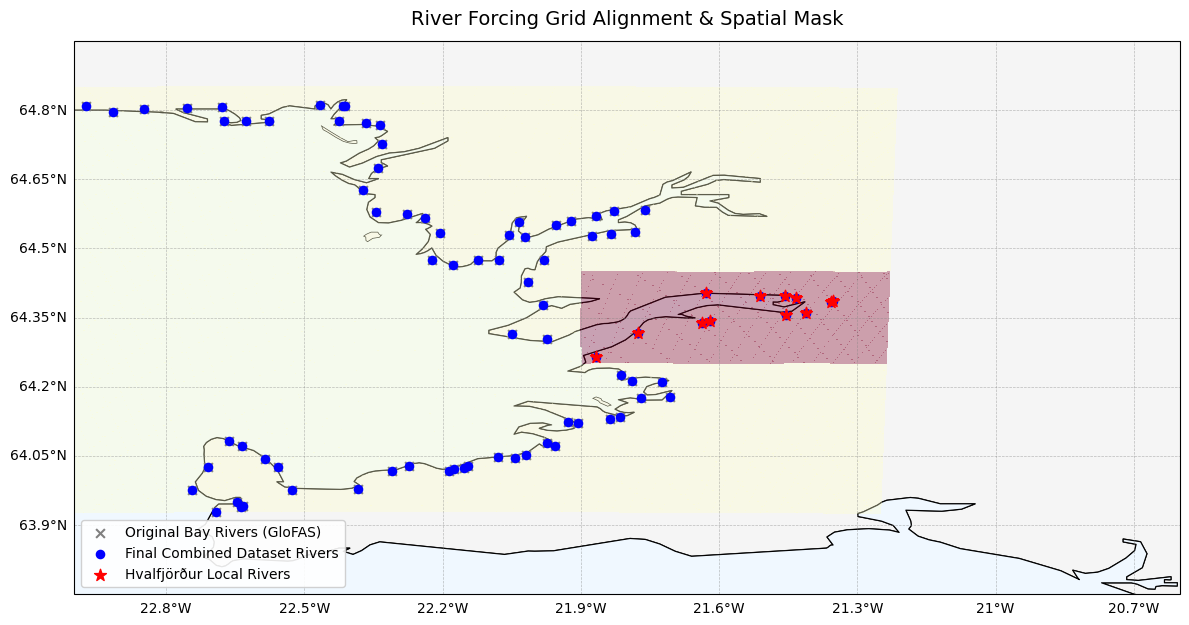

In [32]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------------------------------------------------
# Step 1: Longitude Conversion (0..360 -> -180..180)
# -------------------------------------------------------------------------
# Convert ROMS lon_rho grid to standard longitude for Cartopy
lon_rho_deg = np.where(
    ds_grid["lon_rho"] > 180, ds_grid["lon_rho"] - 360, ds_grid["lon_rho"]
)
lat_rho_deg = ds_grid["lat_rho"].values

# -------------------------------------------------------------------------
# Step 2: Extract 2D River Locations
# -------------------------------------------------------------------------
# Collapse river_time to ensure 2D spatial boolean indexing
bay_mask_2d = (ds_bay_monthly["river_index"] > 0).any(dim="river_time").values
hval_mask_2d = (ds_hval_aligned["river_index"] > 0).any(dim="river_time").values
combined_mask_2d = (ds_combined["river_index"] > 0).any(dim="river_time").values

# Extract lat/lon coordinates for active river cells
bay_lats, bay_lons = lat_rho_deg[bay_mask_2d], lon_rho_deg[bay_mask_2d]
hval_lats, hval_lons = lat_rho_deg[hval_mask_2d], lon_rho_deg[hval_mask_2d]
comb_lats, comb_lons = (
    lat_rho_deg[combined_mask_2d],
    lon_rho_deg[combined_mask_2d],
)

# -------------------------------------------------------------------------
# Step 3: Plot on Cartopy Map
# -------------------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(12, 10), subplot_kw={"projection": ccrs.PlateCarree()}
)

# Add geographical features
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", edgecolor="black", zorder=1)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=1)
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=2)

# 1. Overlay the Hvalfjörður Bounding Box / Grid Mask shading
ax.pcolormesh(
    lon_rho_deg,
    lat_rho_deg,
    fjord_grid_mask,
    transform=ccrs.PlateCarree(),
    cmap="YlOrRd",
    alpha=0.35,
    zorder=2,
)

# 2. Plot original GloFAS Bay rivers (gray crosses)
ax.scatter(
    bay_lons,
    bay_lats,
    color="gray",
    marker="x",
    s=40,
    label="Original Bay Rivers (GloFAS)",
    transform=ccrs.PlateCarree(),
    zorder=3,
)

# 3. Plot active combined rivers in the final dataset (blue circles)
ax.scatter(
    comb_lons,
    comb_lats,
    color="blue",
    marker="o",
    s=35,
    label="Final Combined Dataset Rivers",
    transform=ccrs.PlateCarree(),
    zorder=4,
)

# 4. Highlight local Hvalfjörður rivers (red stars)
ax.scatter(
    hval_lons,
    hval_lats,
    color="red",
    marker="*",
    s=80,
    label="Hvalfjörður Local Rivers",
    transform=ccrs.PlateCarree(),
    zorder=5,
)

# Zoom into the local region around Hvalfjörður & Faxaflói Bay
lon_center, lat_center = -21.8, 64.35
ax.set_extent(
    [lon_center - 1.2, lon_center + 1.2, lat_center - 0.6, lat_center + 0.6],
    crs=ccrs.PlateCarree(),
)

# Add gridlines and title
gl = ax.gridlines(
    draw_labels=True, linewidth=0.5, color="gray", alpha=0.5, linestyle="--"
)
gl.top_labels = False
gl.right_labels = False

plt.title("River Forcing Grid Alignment & Spatial Mask", fontsize=14, pad=12)
plt.legend(loc="lower left", framealpha=0.9, fontsize=10)
plt.tight_layout()
plt.show()

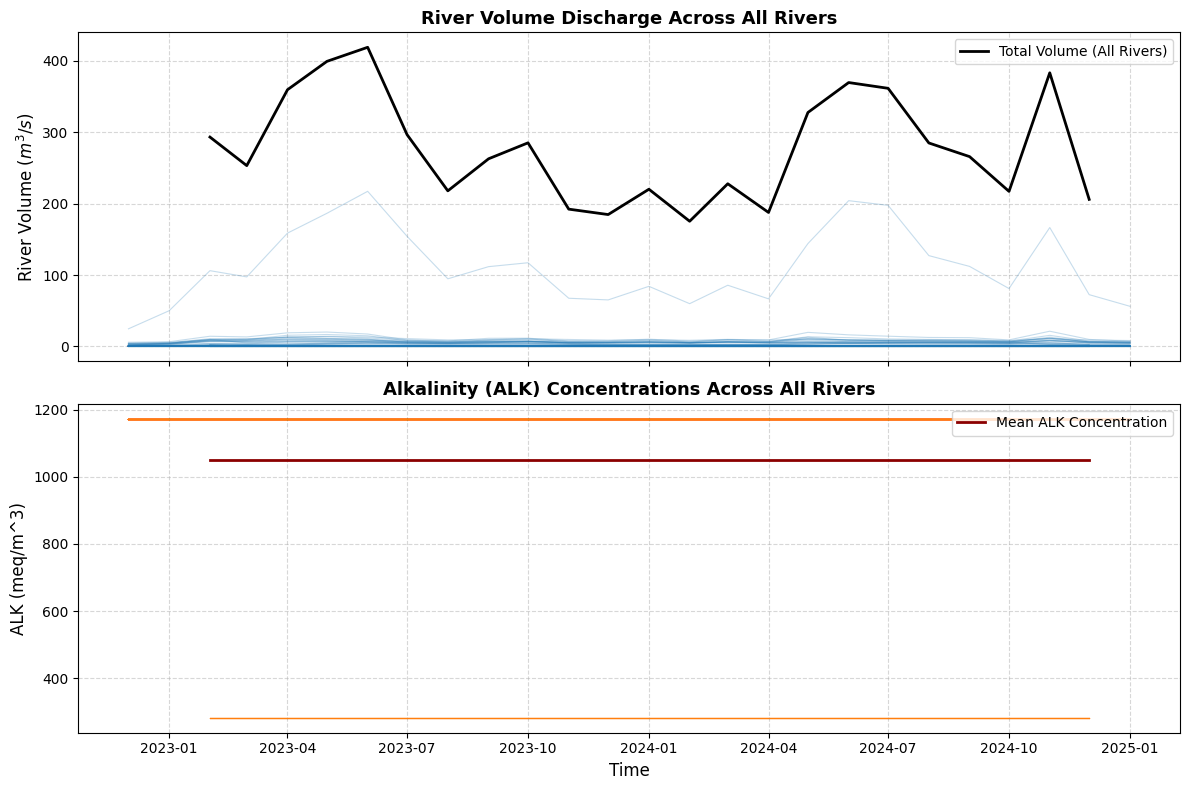

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------------------------------------------------
# Step 1: Extract ALK Tracer Index
# -------------------------------------------------------------------------
# Find the tracer index for 'ALK' (or 'alk' / 'alkalinity')
tracer_names = combined_ds['tracer_name'].values
alk_idx = np.where((tracer_names == 'ALK') | (tracer_names == 'alk'))[0]

if len(alk_idx) == 0:
    raise ValueError(f"Alkalinity tracer 'ALK' not found. Available tracers: {tracer_names}")

alk_idx = alk_idx[0]

# -------------------------------------------------------------------------
# Step 2: Extract Data for Plotting
# -------------------------------------------------------------------------
# Time axis (convert datetime64 or river_time to dates)
time_axis = combined_ds['abs_time'].values

# Volume: shape (river_time, nriver)
volume = combined_ds['river_volume'].values

# ALK Tracer: shape (river_time, ntracers, nriver) -> slice ALK: (river_time, nriver)
alk_tracer = combined_ds['river_tracer'][:, alk_idx, :].values

# -------------------------------------------------------------------------
# Step 3: Plot Volume and Alkalinity (2 Subplots)
# -------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# --- Top Plot: River Volume ---
# Plot each river thin/transparent
ax1.plot(time_axis, volume, color='tab:blue', alpha=0.25, linewidth=0.8)
# Overlay the total bay discharge (sum across all rivers)
total_volume = np.sum(volume, axis=1)
ax1.plot(time_axis, total_volume, color='black', linewidth=2.0, label='Total Volume (All Rivers)')

ax1.set_ylabel('River Volume ($m^3/s$)', fontsize=12)
ax1.set_title('River Volume Discharge Across All Rivers', fontsize=13, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper right')

# --- Bottom Plot: ALK Tracer ---
# Plot each river thin/transparent
ax2.plot(time_axis, alk_tracer, color='tab:orange', alpha=0.25, linewidth=0.8)
# Overlay the mean ALK concentration across all rivers
mean_alk = np.mean(alk_tracer, axis=1)
ax2.plot(time_axis, mean_alk, color='darkred', linewidth=2.0, label='Mean ALK Concentration')

# Get unit string if present
alk_unit = combined_ds['tracer_unit'].values[alk_idx] if 'tracer_unit' in combined_ds else 'mmol/m^3'
ax2.set_ylabel(f'ALK ({alk_unit})', fontsize=12)
ax2.set_xlabel('Time', fontsize=12)
ax2.set_title('Alkalinity (ALK) Concentrations Across All Rivers', fontsize=13, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [35]:
riv.to_netcdf(project+model_name+"_river_combied.nc")

In [36]:
project+model_name+"_river_combied.nc"

'/anvil/projects/x-ees250129/x-uheede/INPUT_files/Iceland2_MARBL_2024/RT_EMOD/Iceland2_river_combied.nc'